# 02 · Embedding – biến token id thành vector

**Vị trí trong luồng dữ liệu:** văn bản → token → **embedding** (+ vị trí) → N khối Transformer → logits → token tiếp theo

Token id chỉ là số thứ tự: id 812 không "gần" id 813 hơn id 5. **Embedding** gán cho mỗi token một vector nhiều
chiều. Trong không gian vector đó, các token có vai trò giống nhau có thể nằm gần nhau, và mạng nơ-ron tính toán
được trên các vector này.

Trong notebook này bạn sẽ:

1. Thấy `nn.Embedding` thực chất chỉ là một bảng tra cứu (tương đương nhân vector one-hot với một ma trận).
2. Nạp vector tiếng Việt có sẵn (fastText `cc.vi.300`) và trực quan hóa bằng PCA, t-SNE.
3. Làm hai thử nghiệm: **(a)** embedding học từ đầu, **(b)** khởi tạo từ fastText với cờ `freeze` / `finetune`, rồi so sánh.

⏱ Thời gian chạy: khoảng 2 phút (lần đầu tải thêm ~35 MB vector fastText).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from torch import nn

from vietformer import viz
from vietformer.data import encode_corpus, get_tokenizer
from vietformer.embedding import TokenEmbedding
from vietformer.model import GPTConfig, MiniGPT
from vietformer.train import split_train_val, train
from vietformer.utils import set_seed
from vietformer.word_vectors import build_embedding_matrix, load_word_vectors

viz.set_style()
set_seed(42)
tokenizer = get_tokenizer()  # tokenizer BPE 4000 đã huấn luyện ở notebook 01

## 1. Embedding là một bảng tra cứu

`nn.Embedding(vocab_size, dim)` giữ một ma trận `W` kích thước `vocab_size × dim`. Tra token id `i` đơn giản là lấy
**hàng thứ i** của `W`. Viết theo kiểu đại số tuyến tính: biểu diễn token bằng vector **one-hot** (toàn số 0, riêng
vị trí `i` là 1) rồi nhân với `W` – kết quả y hệt, chỉ chậm hơn nhiều.

In [2]:
ids = torch.tensor(tokenizer.encode("Trăm năm trong cõi người ta"))
print("token id:", ids.tolist(), "→", tokenizer.display_tokens(ids))

emb = TokenEmbedding(vocab_size=tokenizer.vocab_size, d_model=4)  # chỉ 4 chiều cho dễ nhìn
vectors = emb(ids)                                                  # (T,) -> (T, 4)
print("\nKết quả tra bảng, shape", tuple(vectors.shape))
print(vectors.detach())

one_hot = F.one_hot(ids, tokenizer.vocab_size).float()             # (T, vocab_size)
print("\none-hot @ W cho cùng kết quả?", torch.allclose(one_hot @ emb.table.weight, vectors))

token id: [712, 242, 168, 917, 72, 200] → ['Trăm', 'năm', 'trong', 'cõi', 'người', 'ta']

Kết quả tra bảng, shape (6, 4)
tensor([[-0.9860,  1.4866,  0.1471, -1.3660],
        [-0.2627,  0.9315, -0.4593, -0.9419],
        [ 2.1296, -1.5181,  0.1387, -1.1798],
        [-1.5499,  0.3022, -0.3473, -0.2026],
        [ 0.9733, -1.0151, -0.5419, -0.4410],
        [ 0.9213,  0.5282, -0.0082, -1.4493]])

one-hot @ W cho cùng kết quả? True


Trong mô hình thật, đầu vào là một batch token id kích thước `(B, T)` và đầu ra là `(B, T, d_model)`. Với
`vocab_size = 4000` và `d_model = 128`, riêng bảng này đã có 512.000 tham số, gần 30% mô hình MiniGPT ở notebook 07.

In [3]:
emb = TokenEmbedding(tokenizer.vocab_size, d_model=128)
batch = torch.randint(0, tokenizer.vocab_size, (2, 5))  # B = 2 chuỗi, mỗi chuỗi T = 5 token
print("vào:", tuple(batch.shape), "→ ra:", tuple(emb(batch).shape))
print("số tham số:", sum(p.numel() for p in emb.parameters()))

vào: (2, 5) → ra: (2, 5, 128)
số tham số: 512000


Lúc khởi tạo, các vector là ngẫu nhiên nên chưa mang ý nghĩa gì. Chúng chỉ "có nghĩa" sau khi được huấn luyện cùng
mô hình (thử nghiệm a), hoặc nếu ta lấy sẵn vector đã được huấn luyện trên dữ liệu lớn (thử nghiệm b).

## 2. Vector tiếng Việt có sẵn: fastText `cc.vi.300`

[fastText](https://fasttext.cc/docs/en/crawl-vectors.html) (Facebook AI Research) công bố vector 300 chiều cho 157
ngôn ngữ, học trên Common Crawl và Wikipedia (giấy phép CC BY-SA 3.0). Bản tiếng Việt có 2 triệu "từ", file nén
nặng 1,2 GB, nhưng các từ được **xếp theo tần suất giảm dần**. Vì vậy `download_fasttext_subset` chỉ đọc dần
(stream) phần đầu file cho tới khi đủ 50.000 từ (~35 MB tải về), rồi lưu bản rút gọn vào `data/`.

Ba điều cần biết khi dùng bộ vector này:

* **Mức âm tiết:** fastText tách tiếng Việt theo khoảng trắng, nên có `hoàng` và `đế` nhưng không có `hoàng_đế`.
  Vector của từ ghép được tính bằng **trung bình** vector các âm tiết (`WordVectors.phrase_vector`).
* **NFC:** khi tải lần đầu, hàm in ra số từ *không ở dạng NFC*: có tới hàng nghìn từ như vậy! Không chuẩn hóa thì
  tra `"người"` (NFC) sẽ trượt mất vector của `"người"` (NFD).
* **Dự phòng:** nếu không tải được (mất mạng, bị chặn...), `load_word_vectors` tự chuyển sang **word2vec** huấn
  luyện ngay trên Truyện Kiều (`train_word2vec` trong `word_vectors.py`). Khi đó các hình bên dưới kém ý nghĩa hơn
  nhiều, vì corpus quá nhỏ và thiếu hẳn các từ hiện đại như "Sài Gòn".

In [4]:
wv = load_word_vectors()
print(f"Nguồn: {wv.source} – {len(wv)} từ × {wv.dim} chiều")

Đang đọc 50000 từ đầu tiên của https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.vi.300.vec.gz (không tải cả file 1,2 GB) ...


  ... 10000/50000 từ


  ... 20000/50000 từ


  ... 30000/50000 từ


  ... 40000/50000 từ


  ... 50000/50000 từ
Đã đọc 69592 dòng: 2627 từ không ở dạng NFC; bỏ 19592 từ trùng sau NFC hoặc không phải chữ/dấu câu.
Đã lưu /home/bien/bien/viet-transformer-from-scratch/data/fasttext_vi_50k.npz (31 MB)
Nguồn: fastText cc.vi.300 – 50000 từ × 300 chiều


### Láng giềng gần nhất

Độ tương đồng **cosine** giữa hai vector `u`, `v` là `u·v / (|u|·|v|)`: bằng 1 khi cùng hướng, gần 0 khi "không liên quan".

In [5]:
for word in ["vua", "chó", "nàng", "Sài_Gòn", "Hà_Nội"]:
    try:
        neighbours = ", ".join(f"{w} ({s:.2f})" for w, s in wv.most_similar(word, topn=6))
    except KeyError:
        neighbours = "(không có vector)"
    print(f"{word:>8} → {neighbours}")

     vua → chúa (0.59), ngai (0.52), triều (0.51), cha (0.49), đức (0.47), hoàng (0.45)
     chó → mèo (0.69), cún (0.66), sói (0.57), sủa (0.57), chú (0.56), thỏ (0.56)
    nàng → hắn (0.70), chàng (0.67), Hắn (0.58), Chàng (0.55), nương (0.55), ngươi (0.54)
 Sài_Gòn → Saigon (0.55), Sàigòn (0.51), Saigòn (0.45), SAIGON (0.42), saigon (0.40), HCM (0.40)
  Hà_Nội → bà (0.43), HN (0.42), Hải (0.41), An (0.41), Bà (0.40), ội (0.40)


Với fastText: `vua` gần `chúa`, `ngai`, `triều`; `chó` gần `mèo`, `cún`, `sói`; `Sài_Gòn` gần các cách viết khác
như `Saigon`, `HCM`. Riêng `Hà_Nội` cho kết quả kém hơn hẳn: trung bình hai vector `Hà` và `Nội` chỉ là xấp xỉ thô
của nghĩa cả từ ghép, vì mỗi âm tiết còn xuất hiện trong rất nhiều từ khác (`Hà Giang`, `nội dung`...).

## 3. Trực quan hóa: PCA và t-SNE

Vector 300 chiều không vẽ trực tiếp được, nên ta chiếu xuống 2 chiều:

* **PCA** (phân tích thành phần chính): phép chiếu *tuyến tính* lên 2 hướng mà dữ liệu trải rộng nhất. Giữ được
  cấu trúc tổng thể, nhưng các cụm có thể chồng lên nhau.
* **t-SNE**: phương pháp *phi tuyến*, cố giữ các điểm gần nhau thì vẫn gần nhau. Tách cụm rõ hơn, nhưng khoảng cách
  giữa các cụm ở xa nhau không còn ý nghĩa, và kết quả phụ thuộc tham số `perplexity`.

Ta lấy 3 nhóm từ, mỗi nhóm một màu và một hình marker:

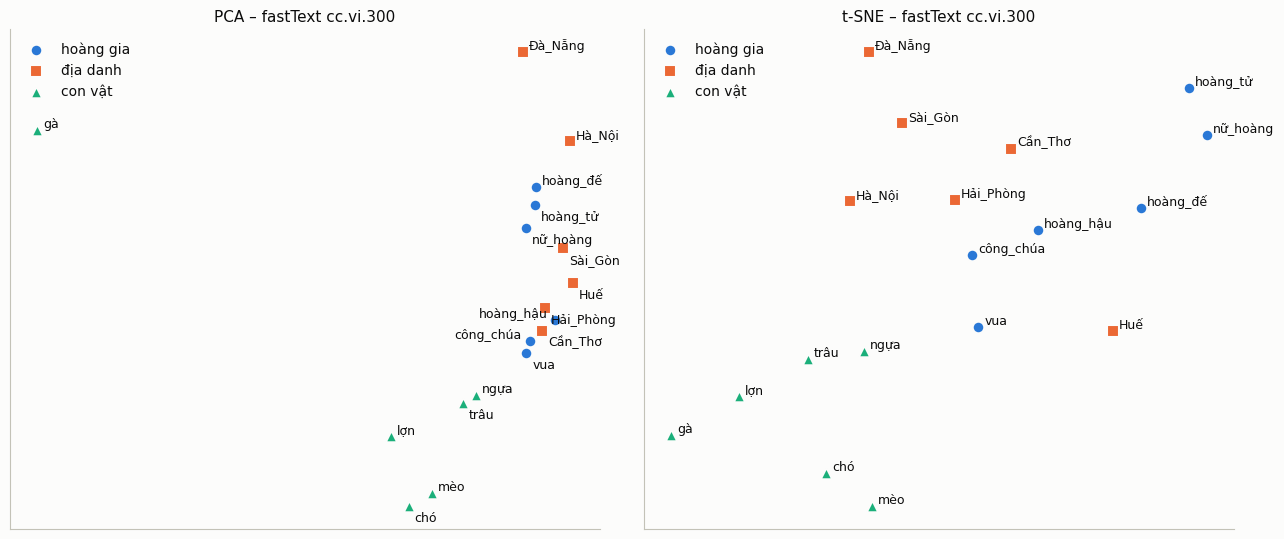

In [6]:
GROUPS = {
    "hoàng gia": ["vua", "hoàng_đế", "nữ_hoàng", "hoàng_hậu", "công_chúa", "hoàng_tử"],
    "địa danh": ["Hà_Nội", "Sài_Gòn", "Huế", "Đà_Nẵng", "Hải_Phòng", "Cần_Thơ"],
    "con vật": ["chó", "mèo", "gà", "trâu", "ngựa", "lợn"],
}


def collect(word_vectors, groups):
    """Lấy vector cho từng từ (từ ghép = trung bình các âm tiết); bỏ qua từ không có vector."""
    words, labels, vecs = [], [], []
    for group, members in groups.items():
        for w in members:
            v = word_vectors.phrase_vector(w)
            if v is None:
                print("bỏ qua (không có vector):", w)
                continue
            words.append(w)
            labels.append(group)
            vecs.append(v)
    return words, labels, np.stack(vecs)


words, labels, X = collect(wv, GROUPS)
pca_2d = PCA(n_components=2).fit_transform(X)
tsne_2d = TSNE(n_components=2, perplexity=min(5, len(words) - 1), init="pca", random_state=0).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
viz.plot_embeddings_2d(pca_2d, words, labels, ax=axes[0], title=f"PCA – {wv.source}")
viz.plot_embeddings_2d(tsne_2d, words, labels, ax=axes[1], title=f"t-SNE – {wv.source}")
plt.tight_layout()
plt.show()

Với fastText, t-SNE tách khá rõ ba cụm hoàng gia, địa danh, con vật. PCA tách được nhóm con vật, nhưng hoàng gia
và địa danh chồng lên nhau một phần: hai hướng chính là chưa đủ để phân biệt mọi thứ trong 300 chiều. Đây là tri
thức fastText học được từ hàng tỉ chữ – Truyện Kiều thậm chí không có lấy một chữ "vua" hay "chó".

## 4. Hai thử nghiệm: (a) học từ đầu vs (b) khởi tạo từ fastText

Để thấy riêng tác dụng của embedding, ta dùng mô hình đơn giản nhất có thể: **bigram** – đoán token tiếp theo chỉ
từ embedding của token hiện tại (chưa có attention, chưa nhìn ngữ cảnh). Mô hình chỉ gồm `TokenEmbedding` và một
lớp `Linear`, nên huấn luyện chỉ mất vài chục giây.

* **(a) học từ đầu:** bảng 4000 × 128 khởi tạo ngẫu nhiên, học cùng mô hình.
* **(b) fastText:** bảng 4000 × 300 chép từ fastText, sau đó một lớp `Linear` 300 → 128 để giảm chiều. Hai biến thể:
  * `freeze=True`: giữ nguyên bảng, chỉ học lớp chiếu và lớp đầu ra;
  * `freeze=False` (finetune): học tiếp cả bảng.

Cả ba biến thể đều dùng chung lớp `TokenEmbedding` (`src/vietformer/embedding.py`) và chung dataclass `GPTConfig`;
hai trường `pretrained_dim` và `freeze_embedding` quyết định biến thể nào được tạo.

**Bước 1:** xây ma trận khởi tạo. Token `▁người` lấy vector của `người`. Token là mảnh âm tiết (`iế`, `ướ`...) hoặc
token đặc biệt (`<unk>`, `<n>`) không có trong fastText nên được khởi tạo ngẫu nhiên.

In [7]:
matrix, coverage = build_embedding_matrix(tokenizer, wv)
missing = [tokenizer.id_to_piece(i) for i in range(tokenizer.vocab_size)
           if wv.get(tokenizer.id_to_piece(i).replace("▁", "")) is None]
print(f"Ma trận {tuple(matrix.shape)}; {coverage:.1%} token có vector có sẵn")
print("Ví dụ token không có:", missing[:15])

Ma trận (4000, 300); 91.9% token có vector có sẵn
Ví dụ token không có: ['<unk>', '<n>', 'iế', 'ướ', 'iề', 'òn', 'iết', 'iệ', 'ẳng', 'ửa', 'ạc', 'uố', 'iê', 'ỗi', 'ầy']


**Bước 2:** định nghĩa mô hình bigram và huấn luyện 3 biến thể (hàm `train` sẽ được giải thích kỹ ở notebook 07;
ở đây chỉ cần biết nó in ra loss trên tập **val** – phần cuối Truyện Kiều mà mô hình không được học).

In [8]:
class BigramLM(nn.Module):
    """Mô hình đơn giản nhất: đoán token tiếp theo CHỈ từ embedding của token hiện tại."""

    def __init__(self, config: GPTConfig):
        super().__init__()
        self.config = config
        self.tok_emb = TokenEmbedding(config.vocab_size, config.d_model, config.pretrained_dim, config.freeze_embedding)
        self.head = nn.Linear(config.d_model, config.vocab_size)
        self.apply(MiniGPT._init_weights)  # khởi tạo giống MiniGPT để so sánh công bằng

    def forward(self, idx, targets=None):
        logits = self.head(self.tok_emb(idx))  # (B, T) -> (B, T, d_model) -> (B, T, vocab_size)
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return logits, loss


data = encode_corpus(tokenizer)
train_data, val_data = split_train_val(data)

variants = {
    "(a) học từ đầu": GPTConfig(vocab_size=tokenizer.vocab_size, d_model=128),
    "(b) fastText, freeze": GPTConfig(vocab_size=tokenizer.vocab_size, d_model=128,
                                      pretrained_dim=wv.dim, freeze_embedding=True),
    "(b) fastText, finetune": GPTConfig(vocab_size=tokenizer.vocab_size, d_model=128,
                                        pretrained_dim=wv.dim, freeze_embedding=False),
}
models, histories = {}, {}
for name, config in variants.items():
    set_seed(0)
    model = BigramLM(config)
    if config.pretrained_dim:
        model.tok_emb.load_vectors(matrix)
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    histories[name] = train(model, train_data, val_data, max_steps=1000, eval_interval=100, verbose=False)
    models[name] = model
    print(f"{name:24} {n_trainable:>9,} tham số được học | val loss tốt nhất "
          f"{histories[name]['best_val_loss']:.3f} (bước {histories[name]['best_step']})")

(a) học từ đầu           1,028,000 tham số được học | val loss tốt nhất 5.491 (bước 800)


(b) fastText, freeze       554,400 tham số được học | val loss tốt nhất 5.702 (bước 900)


(b) fastText, finetune   1,754,400 tham số được học | val loss tốt nhất 5.814 (bước 200)


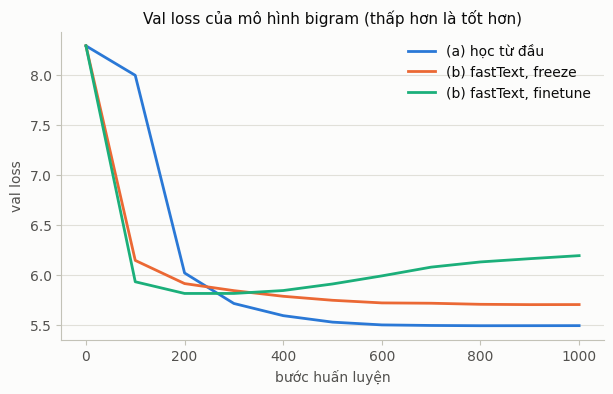

In [9]:
viz.plot_loss_comparison(histories, key="val_loss", title="Val loss của mô hình bigram (thấp hơn là tốt hơn)")
plt.show()

Kết quả có thể làm bạn bất ngờ: **(a) học từ đầu cho val loss thấp nhất**. fastText được huấn luyện trên hàng tỉ
chữ, sao lại thua? Hãy tách val loss theo mức độ "quen" của token hiện tại – nó đã xuất hiện bao nhiêu lần trong tập train?

In [10]:
train_counts = torch.bincount(train_data, minlength=tokenizer.vocab_size)
x, y = val_data[:-1].unsqueeze(0), val_data[1:].unsqueeze(0)  # (1, N): mỗi vị trí đoán token kế tiếp
seen = train_counts[x[0]]                                     # token hiện tại xuất hiện bao nhiêu lần khi train
buckets = {
    "chưa từng gặp": seen == 0,
    "1–3 lần": (seen >= 1) & (seen <= 3),
    "4–20 lần": (seen >= 4) & (seen <= 20),
    "> 20 lần": seen > 20,
}

print(f"{'':24}" + "".join(f"{b:>15}" for b in buckets))
print(f"{'số vị trí trong val':24}" + "".join(f"{int(m.sum()):>15}" for m in buckets.values()))
for name, model in models.items():
    model.eval()
    with torch.no_grad():
        logits, _ = model(x)
        loss_per_position = F.cross_entropy(logits[0], y[0], reduction="none")
    print(f"{name:24}" + "".join(f"{loss_per_position[m].mean():>15.2f}" for m in buckets.values()))

                          chưa từng gặp        1–3 lần       4–20 lần       > 20 lần
số vị trí trong val                  89            332            872           1676
(a) học từ đầu                     8.18           6.50           5.95           4.90
(b) fastText, freeze               7.51           6.64           6.28           5.12
(b) fastText, finetune             7.32           6.97           6.53           5.13


Đọc bảng và đồ thị ở trên:

* **Lúc đầu fastText học nhanh hơn hẳn** (ở bước 100, val loss của hai biến thể (b) đã quanh 6, của (a) vẫn còn 8):
  vector có sẵn cho mô hình một điểm xuất phát tốt.
* Với token **chưa từng gặp khi train**, fastText giúp rất rõ (loss khoảng 7,3–7,5 so với 8,2): ở mô hình (a), vector
  của token đó vẫn là số ngẫu nhiên lúc khởi tạo, còn (b) biết token đó "giống" những token nào nhờ hàng tỉ chữ đã đọc.
* Với token **đã gặp nhiều lần**, vector học thẳng từ Truyện Kiều lại tốt hơn. fastText học từ văn bản web hiện đại,
  nơi `nàng` gần `hắn` vì cùng là đại từ; còn mô hình bigram cần biết chữ nào hay *đứng sau* `nàng` trong thơ lục bát –
  một loại thông tin khác. Hiện tượng này gọi là **lệch miền dữ liệu** (domain mismatch).
* Token quen chiếm phần lớn tập val, nên tính tổng thì (a) thắng. Bản finetune còn overfit sớm (val loss thấp nhất ở
  khoảng bước 200 rồi tăng dần): nó có nhiều tham số nhất (1,75 triệu) để "học thuộc" 27 nghìn token.

### Embedding học được trông thế nào?

Lấy vài nhóm từ **có trong Truyện Kiều**, vẽ PCA cho bảng embedding của mô hình (a) (học từ đầu, 128 chiều) và
của fastText gốc (300 chiều):

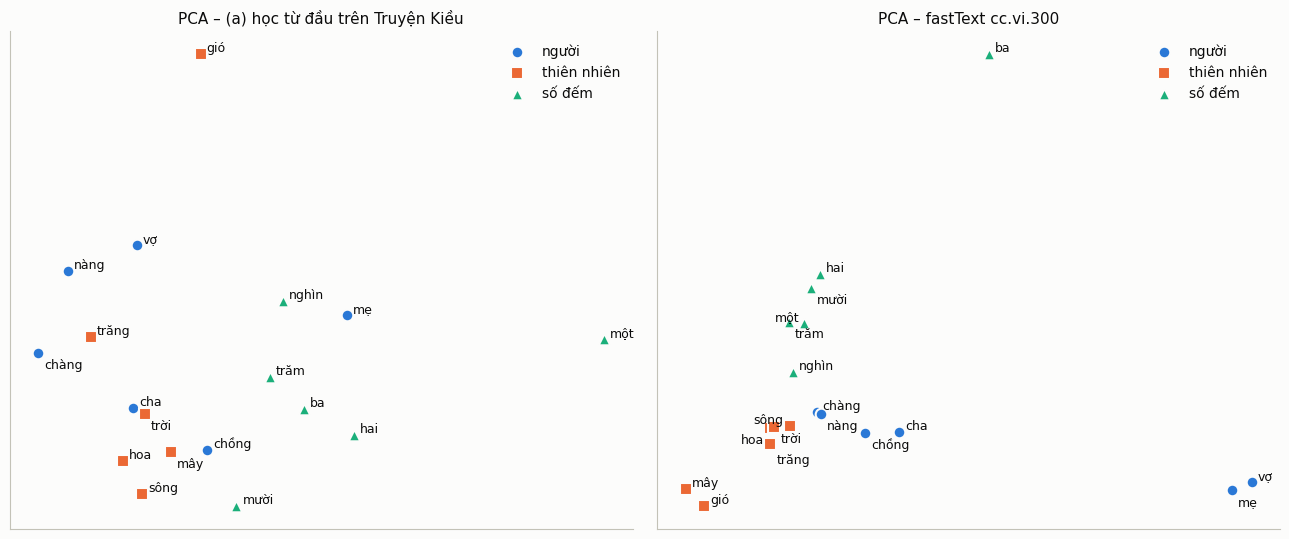

In [11]:
KIEU_GROUPS = {
    "người": ["chàng", "nàng", "cha", "mẹ", "vợ", "chồng"],
    "thiên nhiên": ["hoa", "trăng", "mây", "gió", "sông", "trời"],
    "số đếm": ["một", "hai", "ba", "mười", "trăm", "nghìn"],
}
table_a = models["(a) học từ đầu"].tok_emb.table.weight.detach()


def scratch_vectors(groups):
    """Vector trong bảng embedding của mô hình (a) cho các từ là đúng một token."""
    words, labels, vecs = [], [], []
    for group, members in groups.items():
        for w in members:
            ids = tokenizer.encode(w)
            if len(ids) == 1:
                words.append(w)
                labels.append(group)
                vecs.append(table_a[ids[0]].numpy())
    return words, labels, np.stack(vecs)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (title, (w, l, X)) in zip(axes, [("(a) học từ đầu trên Truyện Kiều", scratch_vectors(KIEU_GROUPS)),
                                          (wv.source, collect(wv, KIEU_GROUPS))]):
    viz.plot_embeddings_2d(PCA(n_components=2).fit_transform(X), w, l, ax=ax, title=f"PCA – {title}")
plt.tight_layout()
plt.show()

Bên phải (fastText), các số đếm tụ lại, các từ thiên nhiên cũng vậy. `ba` nằm tách xa, có lẽ vì trên web `ba` còn
nghĩa là "bố" (phương ngữ Nam Bộ): một từ nhiều nghĩa nhưng chỉ có một vector. Bên trái (học từ đầu), các nhóm lẫn
vào nhau: mô hình bigram chỉ học "sau chữ này thường là chữ gì", và 27 nghìn token là quá ít để học ra ngữ nghĩa.
Notebook 08 sẽ xem lại embedding của MiniGPT sau khi huấn luyện.

## Tóm tắt

* `nn.Embedding` là một bảng `vocab_size × d_model`; tra token id = lấy một hàng = nhân one-hot với ma trận.
* Vector có sẵn (fastText) mang tri thức từ hàng tỉ chữ, nhưng ở mức âm tiết và từ một miền dữ liệu khác (web hiện đại).
* Gắn vector có sẵn vào mô hình: bảng `vocab × 300` + lớp `Linear` 300 → `d_model`, có thể `freeze` hoặc `finetune`.
* Với mô hình bigram trên Truyện Kiều, embedding học từ đầu thắng về tổng thể; fastText chỉ giúp với token chưa gặp
  khi train. Vector có sẵn không phải phép màu – hãy luôn đo trên tập val.
* Kết luận này phụ thuộc vào mô hình: ở notebook 07, khi lặp lại thử nghiệm trên MiniGPT đầy đủ (có attention nhìn
  ngữ cảnh), kết quả sẽ **đổi chiều**.

**Tiếp theo:** embedding chưa biết token đứng ở *vị trí* nào. Notebook 03 giải quyết điều đó.

---

## Bài tập

Đáp án: `solutions/02_embedding.md`

**Bài 1.** Phép "tương tự" nổi tiếng của word2vec: `vua − đàn_ông + đàn_bà ≈ nữ_hoàng`. Hãy tính vector đó bằng
`wv.phrase_vector(...)` rồi tìm các từ gần nhất bằng `wv.most_similar(vector)`. Kết quả có như kỳ vọng không? Vì sao?

In [12]:
# TODO: tính analogy = vector(vua) - vector(đàn_ông) + vector(đàn_bà)
analogy = None

if analogy is not None:
    print(wv.most_similar(analogy, topn=10))

**Bài 2.** Chạy phương án dự phòng: huấn luyện word2vec trên chính Truyện Kiều bằng
`train_word2vec(load_corpus())` (import từ `vietformer.word_vectors` và `vietformer.data`), rồi xem láng giềng gần
nhất của `nàng`, `hoa`, `trăng`. So sánh với fastText: giống và khác ở đâu?

In [13]:
# TODO: from vietformer.word_vectors import train_word2vec ; from vietformer.data import load_corpus

**Bài 3.** Không chạy code, hãy tính số tham số **được huấn luyện** của 3 biến thể bigram (gợi ý: `Linear(a, b)` có
`a·b + b` tham số; `Linear` chiếu của `TokenEmbedding` không có bias), rồi so với con số đã in ở mục 4.